In [34]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import PIL.Image as Image

In [35]:
# Change this path to use a different image.
image_path = Path("pink.jpeg")

with Image.open(image_path) as image:
    rgb = np.asarray(image, dtype=np.float64)
    grayscale = np.asarray(image.convert("L"), dtype=np.float64)

print(f"Loaded {image_path}: {grayscale.shape[0]} × {grayscale.shape[1]} pixels")


Loaded pink.jpeg: 640 × 960 pixels


In [36]:
# Compute the SVD once, then retain only the first k singular values.
U, singular_gray, Vt = np.linalg.svd(grayscale, full_matrices=False)
ranks = [10, 20, 50, 100]
gray_approx = {}
for rank in ranks:
    k = min(rank, len(singular_gray))
    gray_approx[rank] = (U[:, :k] * singular_gray[:k]) @ Vt[:k, :]


In [37]:
# Compute the SVD once, then retain only the first k singular values.
U, singular_rgb, Vt = np.linalg.svd(rgb.transpose((2, 0, 1)), full_matrices=False)
ranks = [10, 20, 50, 100]
# print(U.shape, singular_rgb.shape, Vt.shape)
rgb_approx = {}
for rank in ranks:
    k = min(rank, singular_rgb.shape[-1])
    rgb_approx[rank] = ((U[:, :, :k] * singular_rgb[:, None, :k]) @ Vt[:, :k, :]).transpose((1, 2, 0))


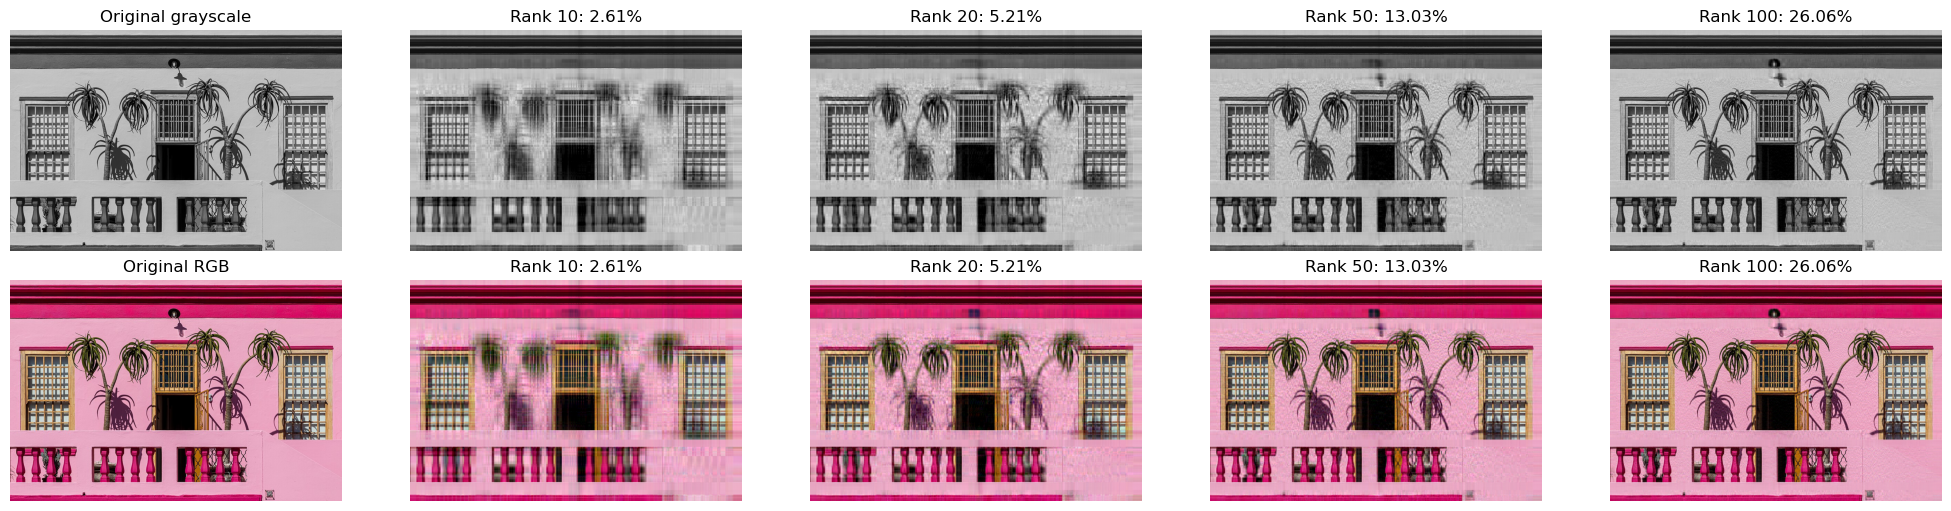

In [ ]:
fig, axes = plt.subplots(2, len(ranks) + 1, figsize=(20, 5), constrained_layout=True)

# Use the same grayscale range for every panel for a fair comparison.
axes[0, 0].imshow(grayscale, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original grayscale")
for ax, rank in zip(axes[0, 1:], ranks):
    ax.imshow(gray_approx[rank], cmap="gray", vmin=0, vmax=255)
    k = min(rank, len(singular_gray))
    relative_size = k * (1 + grayscale.shape[0] + grayscale.shape[1]) / (grayscale.shape[0] * grayscale.shape[1])
    ax.set_title((f"Rank {rank}" if k == rank else f"Rank {rank} (capped at {k})") + f": {relative_size:.2%}")
for ax in axes[0]:
    ax.axis("off")

axes[1, 0].imshow(np.clip(rgb / 255, 0, 1))
axes[1, 0].set_title("Original RGB")
for ax, rank in zip(axes[1, 1:], ranks):
    ax.imshow(np.clip(rgb_approx[rank] / 255, 0, 1))
    k = min(rank, singular_rgb.shape[-1])
    relative_size = k * (1 + rgb.shape[0] + rgb.shape[1]) / (rgb.shape[0] * rgb.shape[1])
    ax.set_title((f"Rank {rank}" if k == rank else f"Rank {rank} (capped at {k})") + f": {relative_size:.2%}")

for ax in axes[1]:
    ax.axis("off")

plt.show()
